## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing the dataset

In [2]:
df=pd.read_csv('placement.csv')
df 

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
95,95,4.3,200.0,0
96,96,4.4,42.0,0
97,97,6.7,182.0,1
98,98,6.3,103.0,1


In [3]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [4]:
df.shape

(100, 4)

## steps
0. Preprocess +EDA + Feature Selection
1. Extract input and output cols
2. Scale the values
3. Train test split
4. Train the model
5. Evaluate the model/model selection
6. Deploy the model

Prerocess

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [6]:
df=df.iloc[:,1:]
df

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0
...,...,...,...
95,4.3,200.0,0
96,4.4,42.0,0
97,6.7,182.0,1
98,6.3,103.0,1


EDA: Exploratory Data Analysis

 we can use logistic regression

Text(0, 0.5, 'iq')

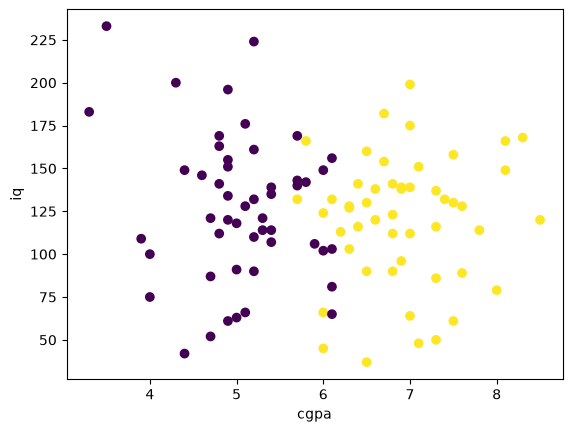

In [7]:
plt.scatter(df['cgpa'],df['iq'] , c=df['placement'])
plt.xlabel('cgpa')
plt.ylabel('iq')

Extract input and output columns

In [8]:
x= df.iloc[:,0:2]
y=df.iloc[:,-1]

In [9]:
print(x.head())
print(y.head())

   cgpa     iq
0   6.8  123.0
1   5.9  106.0
2   5.3  121.0
3   7.4  132.0
4   5.8  142.0
0    1
1    0
2    0
3    1
4    0
Name: placement, dtype: int64


Train test split

In [10]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.1)

In [11]:
x_train

,cgpa,iq
48,6.6,138.0
11,6.9,138.0
35,6.8,90.0
31,3.9,109.0
86,5.1,128.0
...,...,...
65,8.1,166.0
33,6.0,149.0
66,6.9,96.0
2,5.3,121.0


In [12]:
y_train

48    1
11    1
35    1
31    0
86    0
     ..
65    1
33    0
66    1
2     0
54    1
Name: placement, Length: 90, dtype: int64

Scale the values

In [13]:
from sklearn.preprocessing import StandardScaler

In [14]:
scaler=StandardScaler()

In [15]:
x_train=scaler.fit_transform(x_train)
x_train

array([[ 0.52749395,  0.35253942],
       [ 0.80512234,  0.35253942],
       [ 0.71257954, -0.89682095],
       [-1.97116159, -0.40228247],
       [-0.86064802,  0.09225601],
       [-1.04573361, -0.11597072],
       [-0.76810522, -0.37625413],
       [ 0.06477996,  0.19636937],
       [-0.95319082, -1.59958615],
       [ 0.99020794,  0.69090785],
       [-0.02776284, -2.06809629],
       [-1.87861879, -1.28724606],
       [-0.58301963,  0.37856776],
       [-0.02776284, -1.52150113],
       [-0.95319082, -0.1680274 ],
       [-0.76810522,  0.19636937],
       [ 0.06477996,  0.82104955],
       [ 1.45292192, -0.92284929],
       [ 0.99020794, -1.99001127],
       [ 0.52749395, -0.11597072],
       [ 1.63800752, -0.27214076],
       [-0.76810522,  2.59097674],
       [ 0.06477996, -1.54752947],
       [ 0.15732276, -0.29816911],
       [-0.76810522,  0.95119126],
       [-0.67556242, -0.27214076],
       [-1.23081921, -1.8858979 ],
       [-0.86064802,  1.34161637],
       [ 1.17529353,

In [16]:
x_test=scaler.transform(x_test)
x_test

array([[-1.13827641,  1.15941799],
       [ 1.82309312, -1.1831327 ],
       [ 0.89766514, -1.57355781],
       [-1.87861879, -0.63653754],
       [-1.04573361,  1.86218319],
       [ 0.43495115, -0.89682095],
       [-2.52641838,  1.52381476],
       [-1.5084476 , -2.14618131],
       [ 1.45292192,  0.09225601],
       [-0.12030564, -0.48036749]])

Train the model

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
clf=LogisticRegression()

In [19]:
clf.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [20]:
y_predict=clf.predict(x_test)
y_predict

array([0, 1, 1, 0, 0, 1, 0, 0, 1, 0])

In [21]:
y_test

75    0
58    1
64    1
18    0
80    0
79    1
17    0
96    0
30    1
1     0
Name: placement, dtype: int64

In [22]:
from sklearn.metrics import accuracy_score

In [23]:
accuracy_score(y_test, y_predict)

1.0

In [24]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

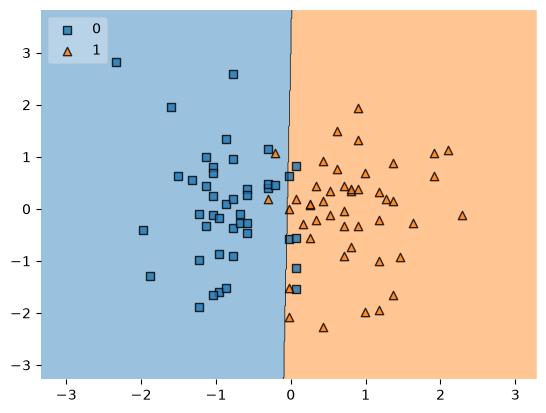

In [25]:
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)